**Name:** Nandini Maheshwari
**BITSID:** 2026AK05287

**Notebook:** ml-assignment-2
**Task:** Model Training

**Problem:** The dataset used here is taken from Kaggle: Online Shoppers Intention. I intend to use it to create a classifier that predicts whether a user's shopping session will end in a purchase, based on their browsing behavior. This is a binary classification problem with the target Revenue (True = purchase).

**About the dataset:** It has 12,330 sessions, 17 features (10 numeric, 7 categorical).

**Approach:** Train and compare five classifiers (Logistic Regression, Decision Tree, KNN, Gaussian Naive Bayes, SVM) on the same stratified train/test split. Evaluate them with Accuracy, AUC, Precision, Recall, F1 and MCC, and save the trained pipelines for the Streamlit app.


## Imports and setting up some constants

In [23]:
# import sys
# print(sys.executable) # should point to the .venv python

# eda & plt imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# train/test split, preprocessing, model imports 
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

RANDOM_STATE = 42
DATA_PATH = "data/online_shoppers_intention.csv"
TEST_DATA_PATH = "test_data.csv"
MODEL_DIR = "model"
TARGET = "Revenue"

NUMERIC_COLS = [
    "Administrative", "Administrative_Duration",
    "Informational", "Informational_Duration",
    "ProductRelated", "ProductRelated_Duration",
    "BounceRates", "ExitRates", "PageValues", "SpecialDay",
]
CATEGORICAL_COLS = [
    "Month", "OperatingSystems", "Browser", "Region",
    "TrafficType", "VisitorType", "Weekend",
]
assert len(NUMERIC_COLS) + len(CATEGORICAL_COLS) == 17

## Data Loading, Data Cleaning & EDA

In [2]:
df = pd.read_csv(DATA_PATH)
print("shape:", df.shape)
df.head()

shape: (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,False,False
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,False,False
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,False,False
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,False,False
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,True,False


In [3]:
# missing values
print("missins value:", df.isna().sum().sum())
# no. of fully duplicated rows
n_duplicates = df.duplicated().sum()
print("no. of dupicates:", n_duplicates)
# drop duplicates 
df = df.drop_duplicates().reset_index(drop=True)
print("new shape post dropping duplicates:",df.shape)

missins value: 0
no. of dupicates: 125
new shape post dropping duplicates: (12205, 18)


         count  percent
Revenue                
False    10297    84.37
True      1908    15.63


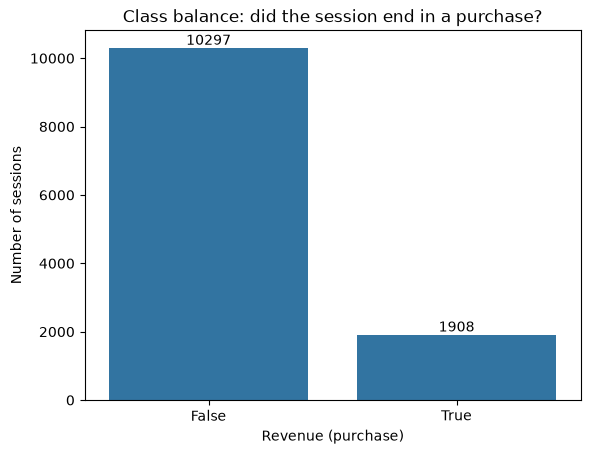

In [12]:
counts = df[TARGET].value_counts()
percent = df[TARGET].value_counts(normalize=True).mul(100).round(2)
print(pd.DataFrame({"count": counts, "percent": percent}))

ax = sns.countplot(data=df, x=TARGET)
ax.bar_label(ax.containers[0])
ax.set_title("Class balance: did the session end in a purchase?")
ax.set_xlabel("Revenue (purchase)")
ax.set_ylabel("Number of sessions")
plt.show()

In [13]:
df[NUMERIC_COLS].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
Administrative,12205.0,2.34,3.33,0.0,0.00,1.00,4.00,27.00
Administrative_Duration,12205.0,81.65,177.49,0.0,0.00,9.00,94.70,3398.75
Informational,12205.0,0.51,1.28,0.0,0.00,0.00,0.00,24.00
Informational_Duration,12205.0,34.83,141.42,0.0,0.00,0.00,0.00,2549.38
ProductRelated,12205.0,32.05,44.59,0.0,8.00,18.00,38.00,705.00
ProductRelated_Duration,12205.0,1206.98,1919.60,0.0,193.00,608.94,1477.15,63973.52
BounceRates,12205.0,0.02,0.05,0.0,0.00,0.00,0.02,0.20
ExitRates,12205.0,0.04,0.05,0.0,0.01,0.02,0.05,0.20
PageValues,12205.0,5.95,18.65,0.0,0.00,0.00,0.00,361.76
SpecialDay,12205.0,0.06,0.20,0.0,0.00,0.00,0.00,1.00


observations:
- all cols with "*_Duration" are heavily skewed.
- PageValues and SpecialDay have a median of 0 - i.e., most sessions have none
- BounceRates and ExitRates values sit between 0 to 0.2

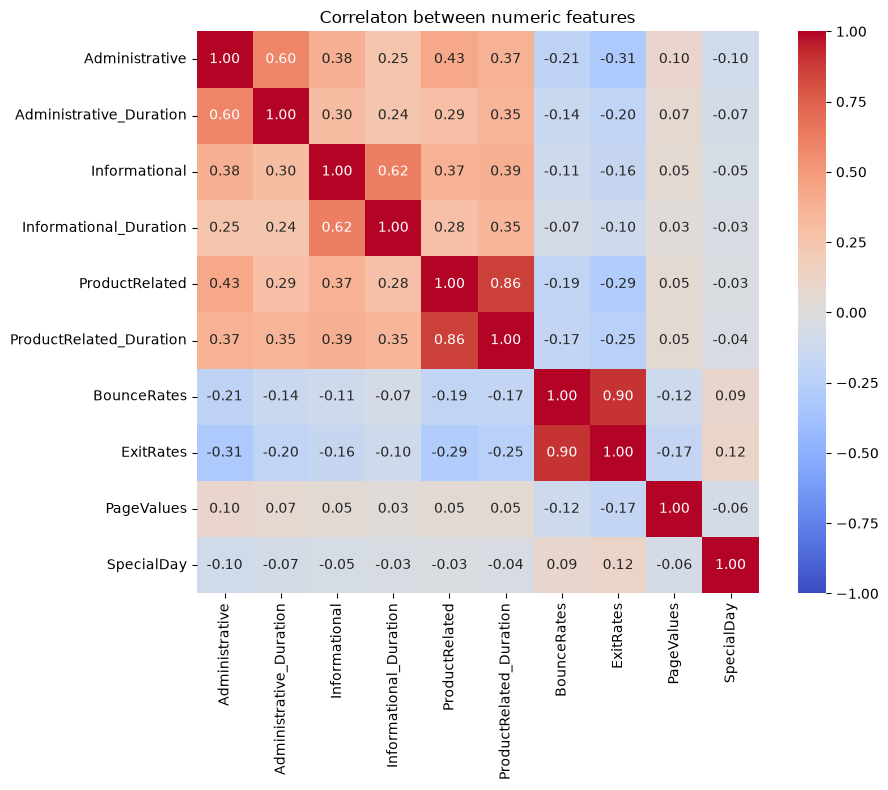

In [14]:
# corr. matrix of NUMERIC_COLS
corr = df[NUMERIC_COLS].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm",
            vmin=-1, vmax=1, square=True)
plt.title("Correlaton between numeric features")
plt.tight_layout()
plt.show()

corr. matrix observartions:
- BounceRates and ExitRates heavily correlated : 0.90
- ProductRelated and ProductRelated_Duration: 0.86
- Administrative and Informational columns with their respective duration cols.: ~ 0.6 

purchase rate: VisitorType
New_Visitor          24.93
Other                19.75
Returning_Visitor    14.09
Name: Revenue, dtype: float64


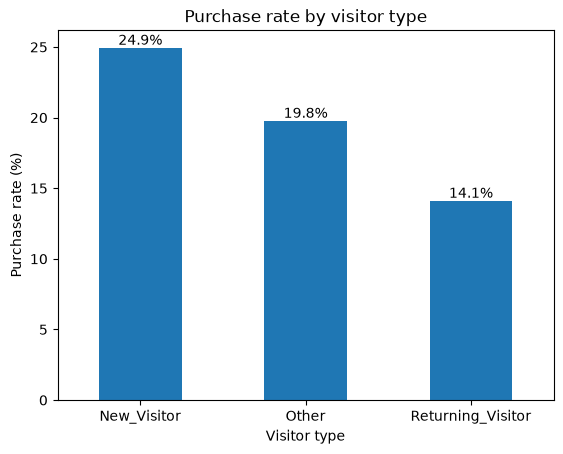

In [15]:
# calc purchase rate by VisitorType
purchase_rate = df.groupby('VisitorType')[TARGET].mean().mul(100).sort_values(ascending=False)

print("purchase rate:", purchase_rate.round(2))

# plt purchase rate
ax = purchase_rate.plot(kind="bar", rot=0)
ax.bar_label(ax.containers[0], fmt="%.1f%%")
ax.set_xlabel("Visitor type")
ax.set_ylabel("Purchase rate (%)")
ax.set_title("Purchase rate by visitor type")
plt.show()

purchase rate observations:
- new visitors purchase rates are highest. They seem to buy the most.
- returning visitor make up considerable amount of traffic but are not great at cnoverting to purchase.

### EDA Notes

- No missing values. Dropped 125 exact duplicate rows → 12205 sessions remain.
- Imbalanced target: only ~15.6% of sessions end in a purchase, so accuracy alone
  will look good even for a weak model. MCC, F1 and recall matter more here.
- Strong correlations: BounceRates–ExitRates (0.9) and ProductRelated–ProductRelated_Duration (0.86).
  This breaks Naive Bayes' independence assumption.
- *Duration* features are heavily skewed, so scaling is needed for KNN and SVM.
- New visitors convert at ~25% vs ~14% for returning visitors.

## Train/test split, test_data.csv

In [18]:
X = df.drop(columns=[TARGET])
y = df[TARGET].astype(int)

assert set(X.columns) == set(NUMERIC_COLS + CATEGORICAL_COLS)

print("X shape:", X.shape)
print(y.value_counts())

X shape: (12205, 17)
Revenue
0    10297
1     1908
Name: count, dtype: int64


In [19]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE,
)

print("X_train:", X_train.shape, " y_train:", y_train.shape)
print("X_test: ", X_test.shape,  " y_test: ", y_test.shape)
print(f"Postive ratio train: {y_train.mean():.4f}   test: {y_test.mean():.4f}")

X_train: (9764, 17)  y_train: (9764,)
X_test:  (2441, 17)  y_test:  (2441,)
Postive ratio train: 0.1563   test: 0.1565


In [21]:
# write and save test data
test_df = X_test.assign(**{TARGET: y_test})
test_df.to_csv(TEST_DATA_PATH, index=False)

print("Saved", TEST_DATA_PATH, "with shape", test_df.shape)

Saved test_data.csv with shape (2441, 18)


In [22]:
check = pd.read_csv(TEST_DATA_PATH)

assert check.shape == (len(X_test), 18)
assert list(check.columns) == list(X.columns) + [TARGET]
assert set(check[TARGET].unique()) <= {0, 1}
assert check["Weekend"].dtype == bool

print(check.dtypes)
print("\ntest_data.csv looks good:", check.shape)

Administrative               int64
Administrative_Duration    float64
Informational                int64
Informational_Duration     float64
ProductRelated               int64
ProductRelated_Duration    float64
BounceRates                float64
ExitRates                  float64
PageValues                 float64
SpecialDay                 float64
Month                          str
OperatingSystems             int64
Browser                      int64
Region                       int64
TrafficType                  int64
VisitorType                    str
Weekend                       bool
Revenue                      int64
dtype: object

test_data.csv looks good: (2441, 18)


## Data Pre-processing

one reusable preprocessor that scales numeric cols. & one-hot encoedes the cateogrical ones.

In [24]:
def make_preprocessor():
    """returns fresh preprocessor; scale numeric columns, one-hot encode categorial cols."""
    return ColumnTransformer(
        transformers= [
            ("num", StandardScaler(), NUMERIC_COLS),
            ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_COLS),
        ],
        remainder="drop"
    )

make_preprocessor()

,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``

In [26]:
pre_check = make_preprocessor()
Xt_train = pre_check.fit_transform(X_train)
Xt_test = pre_check.transform(X_test)

print("transformed train shape:", Xt_train.shape)
print("transformed test shape ", Xt_test.shape)
print("any NaN aftr transform:", bool(np.isnan(Xt_train).any() or np.isnan(Xt_test).any()))


feature_names = pre_check.get_feature_names_out()
n_num = sum(name.startswith("num__") for name in feature_names)
n_cat = sum(name.startswith("cat__") for name in feature_names)
print("Numeric features:", n_num)
print("One-hot features:", n_cat)
print("Month cols:", [n for n in feature_names if n.startswith("cat__Month")])

print("Scaled numeric means on train (~0):",
      Xt_train[:, :n_num].mean(axis=0).round(3))

transformed train shape: (9764, 74)
transformed test shape  (2441, 74)
any NaN aftr transform: False
Numeric features: 10
One-hot features: 64
Month cols: ['cat__Month_Aug', 'cat__Month_Dec', 'cat__Month_Feb', 'cat__Month_Jul', 'cat__Month_June', 'cat__Month_Mar', 'cat__Month_May', 'cat__Month_Nov', 'cat__Month_Oct', 'cat__Month_Sep']
Scaled numeric means on train (~0): [ 0. -0. -0. -0.  0.  0. -0.  0.  0. -0.]
